In [14]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import time   

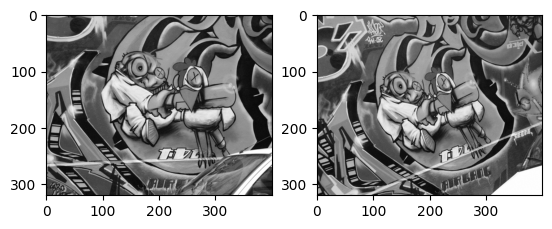

In [15]:
from pathlib import Path

image_dir = next(
    (path for path in (Path("assignment1/data/graf"), Path("data/graf")) if path.is_dir()),
    None,
)
if image_dir is None:
    raise FileNotFoundError("Could not find data/graf relative to the workspace or assignment1 directory")

im1 = cv.imread(str(image_dir / "img1.ppm"), cv.IMREAD_GRAYSCALE)
im2 = cv.imread(str(image_dir / "img2.ppm"), cv.IMREAD_GRAYSCALE)
if im1 is None or im2 is None:
    raise FileNotFoundError(f"Could not load img1.ppm and img2.ppm from {image_dir.resolve()}")

plt.subplot(1, 2, 1)
plt.imshow(im1, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(im2, cmap='gray')
plt.show()



Time taken to compute SIFT features: 0.0460 seconds
Number of keypoints in image 1: 501
Number of keypoints in image 2: 501


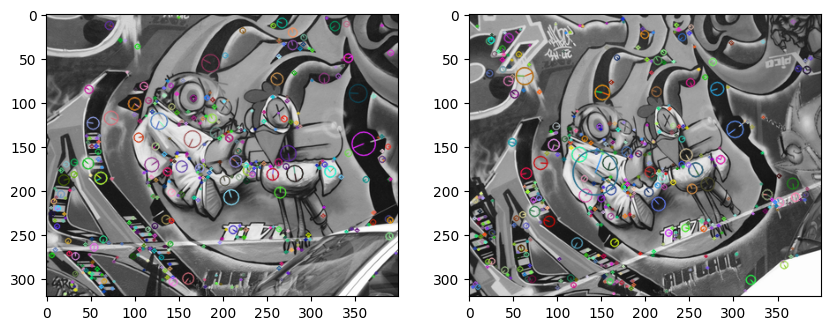

Time taken to compute FAST features: 0.0030 seconds
Number of keypoints in image 1 (FAST): 487
Number of keypoints in image 2 (FAST): 572


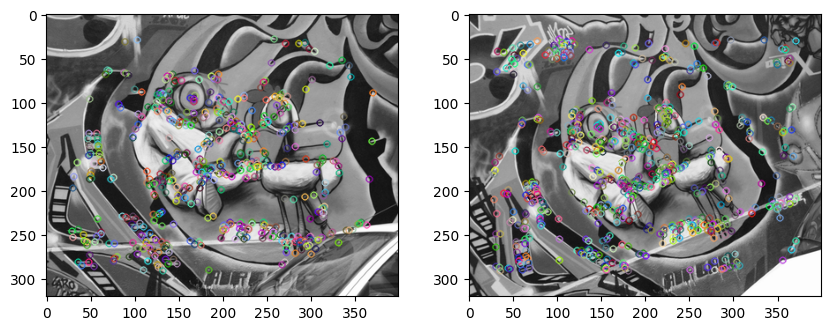

In [16]:
sift = cv.SIFT_create(nfeatures=500, nOctaveLayers=3, contrastThreshold=0.03, edgeThreshold=10, sigma=1.6)
start_time = time.time()
kp1, des1 = sift.detectAndCompute(im1, None)
kp2, des2 = sift.detectAndCompute(im2, None)
end_time = time.time()
print(f"Time taken to compute SIFT features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1: {len(kp1)}")
print(f"Number of keypoints in image 2: {len(kp2)}")

image_with_keypoints1 = cv.drawKeypoints(im1, kp1, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints2 = cv.drawKeypoints(im2, kp2, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_with_keypoints1, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(image_with_keypoints2, cmap='gray')
plt.show()


fast = cv.FastFeatureDetector_create(threshold=50, nonmaxSuppression=True)
start_time = time.time()
kp1_fast = fast.detect(im1, None)
kp2_fast = fast.detect(im2, None)

brief = cv.xfeatures2d.BriefDescriptorExtractor_create()
kp1_fast, des1_fast = brief.compute(im1, kp1_fast)
kp2_fast, des2_fast = brief.compute(im2, kp2_fast)
end_time = time.time()
print(f"Time taken to compute FAST features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (FAST): {len(kp1_fast)}")
print(f"Number of keypoints in image 2 (FAST): {len(kp2_fast)}")

image_with_keypoints1_fast = cv.drawKeypoints(im1, kp1_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints2_fast = cv.drawKeypoints(im2, kp2_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_with_keypoints1_fast, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(image_with_keypoints2_fast, cmap='gray')
plt.show()  


# 2.2 e 2.4
## SIFT e Fast


Time taken to match and verify features: 0.0030 seconds
Mutual ratio-test matches: 220; geometrically consistent: 219
Number of SIFT matches drawn: 20


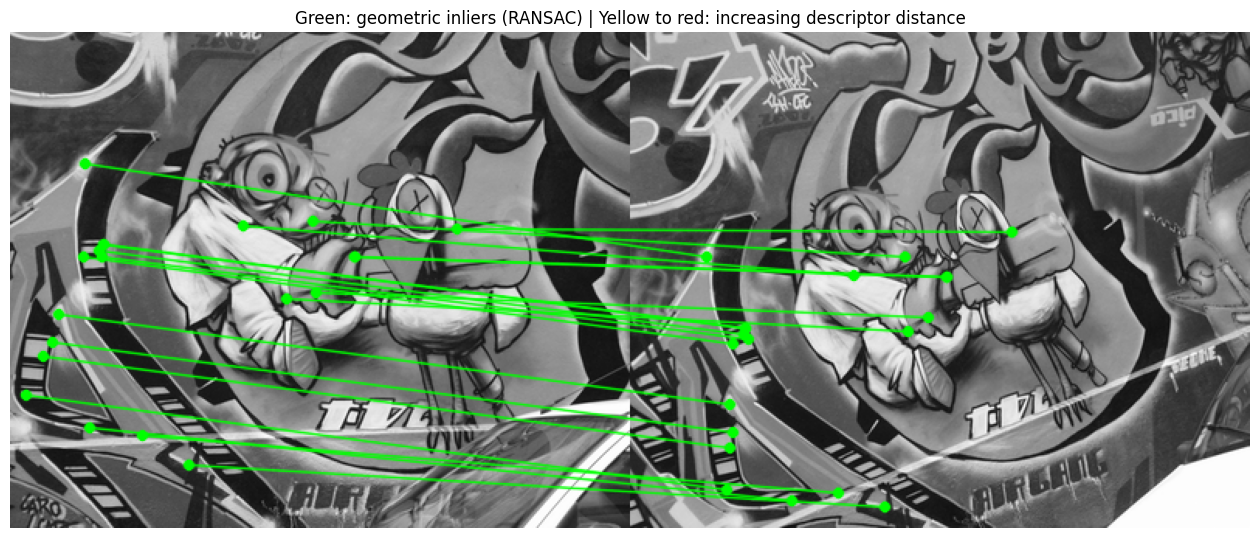

Time taken to match and verify FAST features: 0.0040 seconds
FAST matches after reciprocal + RANSAC: 11
Number of FAST matches drawn: 11


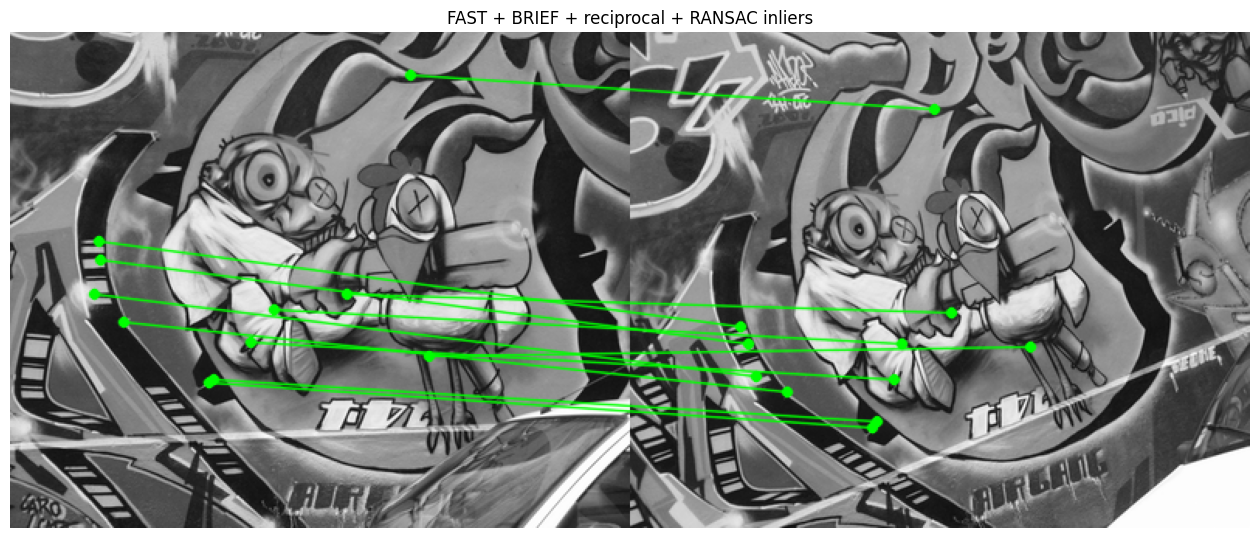

In [17]:
### [SIFT]

matcher = cv.BFMatcher(cv.NORM_L2)
ratio_threshold = 0.75
start_time = time.time()
forward = matcher.knnMatch(des1, des2, k=2)
reverse = matcher.knnMatch(des2, des1, k=2)

# Mutual ratio-test matches
forward_good = {
    m.queryIdx: m
    for pair in forward if len(pair) == 2
    for m, n in [pair]
    if m.distance < ratio_threshold * n.distance
}
reverse_good = {
    m.queryIdx: m
    for pair in reverse if len(pair) == 2
    for m, n in [pair]
    if m.distance < ratio_threshold * n.distance
}
# Find matches that are consistent in both directions
matches = [
    match for match in forward_good.values()
    if match.trainIdx in reverse_good
    and reverse_good[match.trainIdx].trainIdx == match.queryIdx
]
matches.sort(key=lambda match: match.distance)
if len(matches) < 4:
    raise ValueError(f"Only {len(matches)} reliable matches found; at least 4 are needed for geometric verification")

points1 = np.float32([kp1[match.queryIdx].pt for match in matches]).reshape(-1, 1, 2)
points2 = np.float32([kp2[match.trainIdx].pt for match in matches]).reshape(-1, 1, 2)
_, inlier_mask = cv.findHomography(points1, points2, cv.RANSAC, 5.0)
if inlier_mask is None:
    raise RuntimeError("RANSAC could not find a consistent geometric transform for the matches")
inliers = inlier_mask.ravel().astype(bool)
end_time = time.time()
print(f"Time taken to match and verify features: {end_time - start_time:.4f} seconds")
print(f"Mutual ratio-test matches: {len(matches)}; geometrically consistent: {int(inliers.sum())}")

max_matches = 20
matches_to_draw = matches[:max_matches]
draw_inliers = inliers[:max_matches]
distances = np.array([match.distance for match in matches_to_draw], dtype=np.float32)
distance_span = float(np.ptp(distances)) if len(distances) else 0.0
height = max(im1.shape[0], im2.shape[0])
width1 = im1.shape[1]
image_matches = np.zeros((height, width1 + im2.shape[1], 3), dtype=np.uint8)
image_matches[:im1.shape[0], :width1] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
image_matches[:im2.shape[0], width1:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

for index, match in enumerate(matches_to_draw):
    point1 = tuple(np.round(kp1[match.queryIdx].pt).astype(int))
    point2 = tuple(np.round(kp2[match.trainIdx].pt).astype(int) + np.array([width1, 0]))
    if draw_inliers[index]:
        color = (0, 255, 0)
    else:
        relative_distance = (match.distance - distances.min()) / distance_span if distance_span else 0.0
        color = (0, int(255 * (1 - relative_distance)), 255)
    cv.line(image_matches, point1, point2, color, 1, cv.LINE_AA)
    cv.circle(image_matches, point1, 3, color, -1, cv.LINE_AA)
    cv.circle(image_matches, point2, 3, color, -1, cv.LINE_AA)
    
print(f"Number of SIFT matches drawn: {len(matches_to_draw)}")

plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(image_matches, cv.COLOR_BGR2RGB))
plt.title("Green: geometric inliers (RANSAC) | Yellow to red: increasing descriptor distance")
plt.axis("off")
plt.show()

### [Fast]


bf = cv.BFMatcher(cv.NORM_HAMMING)
start_time = time.time()
matches_fast = bf.knnMatch(des1_fast, des2_fast, k=2)


good_matches_fast = []
for m, n in matches_fast:
    if m.distance < ratio_threshold * n.distance:
        good_matches_fast.append(m)

rev_matches_fast = bf.knnMatch(des2_fast, des1_fast, k=2)
good_rev_matches_fast = []
for m, n in rev_matches_fast:
    if m.distance < ratio_threshold * n.distance:
        good_rev_matches_fast.append(m)

reverse_good_fast = {m.queryIdx: m for m in good_rev_matches_fast}

mutual_matches_fast = [
    match for match in good_matches_fast
    if match.trainIdx in reverse_good_fast
    and reverse_good_fast[match.trainIdx].trainIdx == match.queryIdx
]

if len(mutual_matches_fast) < 8:
    raise ValueError(
        f"Only {len(mutual_matches_fast)} reliable FAST matches found; at least 8 are needed for strong geometric verification"
    )

mutual_matches_fast.sort(key=lambda match: match.distance)


pts1_fast = np.float32([kp1_fast[m.queryIdx].pt for m in mutual_matches_fast]).reshape(-1, 1, 2)
pts2_fast = np.float32([kp2_fast[m.trainIdx].pt for m in mutual_matches_fast]).reshape(-1, 1, 2)

_, inlier_mask_fast = cv.findHomography(pts1_fast, pts2_fast, cv.RANSAC, 5.0)

if inlier_mask_fast is None:
    raise RuntimeError("RANSAC could not find a consistent geometric transform for FAST matches")

inliers_fast = inlier_mask_fast.ravel().astype(bool)

mutual_matches_fast = [m for m, keep in zip(mutual_matches_fast, inliers_fast) if keep]

if len(mutual_matches_fast) < 4:
    raise ValueError(f"Only {len(mutual_matches_fast)} inlier matches remain; at least 4 needed.")
end_time = time.time()
print(f"Time taken to match and verify FAST features: {end_time - start_time:.4f} seconds")
print(f"FAST matches after reciprocal + RANSAC: {len(mutual_matches_fast)}")

# 8) Desenhar
max_matches_fast = 20
matches_to_draw_fast = mutual_matches_fast[:max_matches_fast]
height_fast = max(im1.shape[0], im2.shape[0])
width1_fast = im1.shape[1]
image_matches_fast = np.zeros((height_fast, width1_fast + im2.shape[1], 3), dtype=np.uint8)
image_matches_fast[:im1.shape[0], :width1_fast] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
image_matches_fast[:im2.shape[0], width1_fast:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

for match in matches_to_draw_fast:
    pt1 = tuple(np.round(kp1_fast[match.queryIdx].pt).astype(int))
    pt2 = tuple(np.round(kp2_fast[match.trainIdx].pt).astype(int) + np.array([width1_fast, 0]))
    cv.line(image_matches_fast, pt1, pt2, (0, 255, 0), 1, cv.LINE_AA)
    cv.circle(image_matches_fast, pt1, 3, (0, 255, 0), -1, cv.LINE_AA)
    cv.circle(image_matches_fast, pt2, 3, (0, 255, 0), -1, cv.LINE_AA)
    
print(f"Number of FAST matches drawn: {len(matches_to_draw_fast)}")

plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(image_matches_fast, cv.COLOR_BGR2RGB))
plt.title("FAST + BRIEF + reciprocal + RANSAC inliers")
plt.axis("off")
plt.show()




# 2.4
## KAZE e ORB


Time taken to compute KAZE features: 0.1550 seconds
Number of keypoints in image 1 (KAZE): 1271
Number of keypoints in image 2 (KAZE): 1387


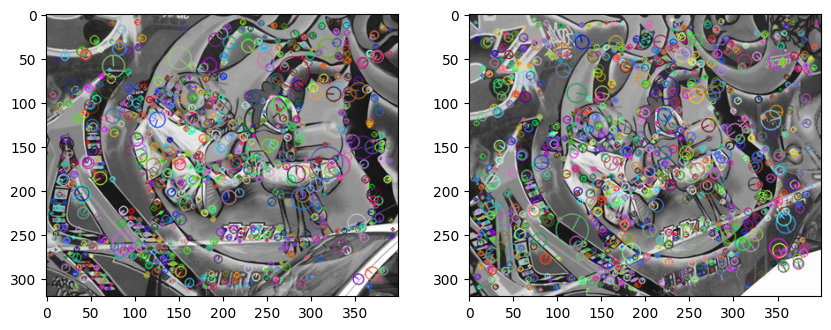

Time taken to compute ORB features: 0.3798 seconds
Number of keypoints in image 1 (ORB): 500
Number of keypoints in image 2 (ORB): 500


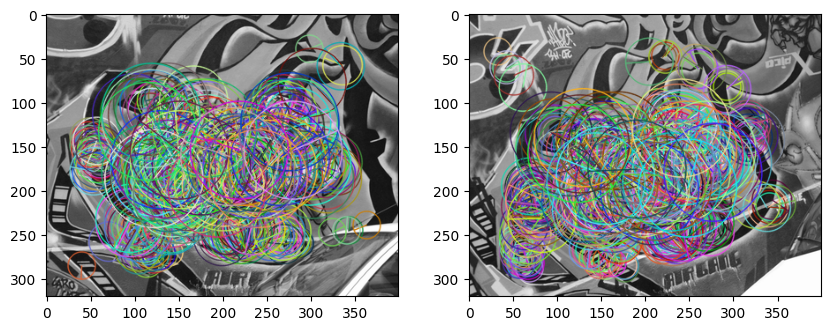

In [24]:
kaze = cv.xfeatures2d.KAZE_create()

start_time = time.time()
kp1_kaze, des1_kaze = kaze.detectAndCompute(im1, None)
kp2_kaze, des2_kaze = kaze.detectAndCompute(im2, None)
end_time = time.time()
print(f"Time taken to compute KAZE features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (KAZE): {len(kp1_kaze)}")
print(f"Number of keypoints in image 2 (KAZE): {len(kp2_kaze)}")

image_kaze_keypoints1 = cv.drawKeypoints(im1, kp1_kaze, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_kaze_keypoints2 = cv.drawKeypoints(im2, kp2_kaze, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_kaze_keypoints1, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(image_kaze_keypoints2, cmap='gray')
plt.show()


Orb = cv.ORB_create(nfeatures=500, scaleFactor=1.2, nlevels=8, edgeThreshold=31, firstLevel=0, WTA_K=2, scoreType=cv.ORB_HARRIS_SCORE, patchSize=31, fastThreshold=20)

start_time = time.time()
kp1_orb, des1_orb = Orb.detectAndCompute(im1, None)
kp2_orb, des2_orb = Orb.detectAndCompute(im2, None)
end_time = time.time()
print(f"Time taken to compute ORB features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (ORB): {len(kp1_orb)}")
print(f"Number of keypoints in image 2 (ORB): {len(kp2_orb)}")

image_orb_keypoints1 = cv.drawKeypoints(im1, kp1_orb, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_orb_keypoints2 = cv.drawKeypoints(im2, kp2_orb, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)    
plt.imshow(image_orb_keypoints1, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(image_orb_keypoints2, cmap='gray')
plt.show()



Time taken to match and verify KAZE features: 0.0080 seconds
KAZE mutual ratio-test matches: 407; geometrically consistent: 406
Number of KAZE matches drawn: 20


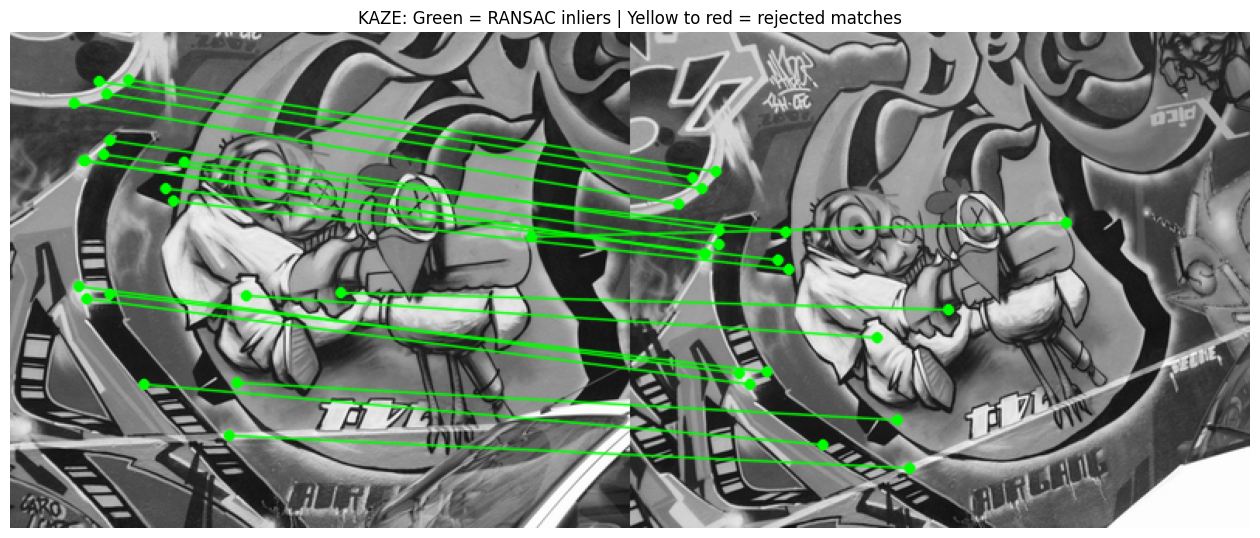

Time taken to match and verify ORB features: 0.0030 seconds
ORB mutual ratio-test matches: 114; geometrically consistent: 114
Number of ORB matches drawn: 20


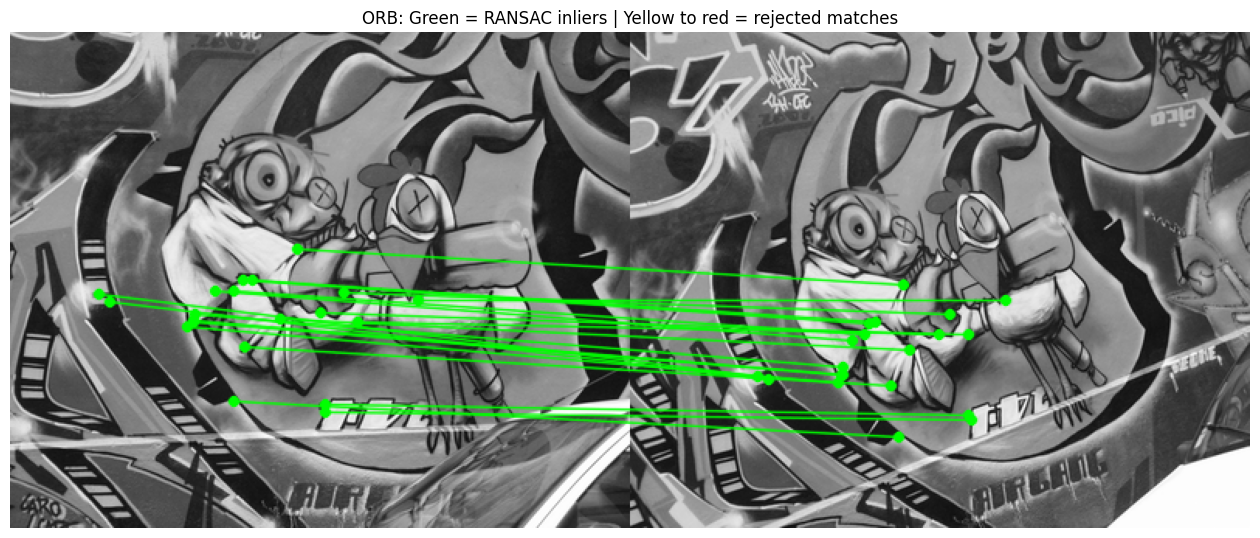

In [26]:
### [KAZE]

bf_kaze = cv.BFMatcher(cv.NORM_L2)
ratio_threshold = 0.75

start_time = time.time()

# Forward matching
matches_kaze = bf_kaze.knnMatch(des1_kaze, des2_kaze, k=2)

good_matches_kaze = []

for pair in matches_kaze:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_matches_kaze.append(m)


# Reverse matching
rev_matches_kaze = bf_kaze.knnMatch(des2_kaze, des1_kaze, k=2)

good_rev_matches_kaze = []

for pair in rev_matches_kaze:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_kaze.append(m)


# Reciprocal matching
reverse_good_kaze = {
    m.queryIdx: m
    for m in good_rev_matches_kaze
}

mutual_matches_kaze = [
    match
    for match in good_matches_kaze
    if match.trainIdx in reverse_good_kaze
    and reverse_good_kaze[match.trainIdx].trainIdx == match.queryIdx
]


if len(mutual_matches_kaze) < 4:
    raise ValueError(
        f"Only {len(mutual_matches_kaze)} reliable KAZE matches found; "
        "at least 4 are needed for geometric verification"
    )


# Sort by descriptor distance
mutual_matches_kaze.sort(key=lambda match: match.distance)


# Extract matching keypoint coordinates
pts1_kaze = np.float32([
    kp1_kaze[m.queryIdx].pt
    for m in mutual_matches_kaze
]).reshape(-1, 1, 2)

pts2_kaze = np.float32([
    kp2_kaze[m.trainIdx].pt
    for m in mutual_matches_kaze
]).reshape(-1, 1, 2)


# Geometric verification using RANSAC
_, inlier_mask_kaze = cv.findHomography(
    pts1_kaze,
    pts2_kaze,
    cv.RANSAC,
    5.0
)

if inlier_mask_kaze is None:
    raise RuntimeError(
        "RANSAC could not find a consistent geometric transform "
        "for KAZE matches"
    )


inliers_kaze = inlier_mask_kaze.ravel().astype(bool)

end_time = time.time()


print(
    f"Time taken to match and verify KAZE features: "
    f"{end_time - start_time:.4f} seconds"
)

print(
    f"KAZE mutual ratio-test matches: {len(mutual_matches_kaze)}; "
    f"geometrically consistent: {int(inliers_kaze.sum())}"
)


# =========================
# Draw matches
# =========================

max_matches_kaze = 20

matches_to_draw_kaze = mutual_matches_kaze[:max_matches_kaze]
draw_inliers_kaze = inliers_kaze[:max_matches_kaze]

distances_kaze = np.array(
    [match.distance for match in matches_to_draw_kaze],
    dtype=np.float32
)

distance_span_kaze = (
    float(np.ptp(distances_kaze))
    if len(distances_kaze)
    else 0.0
)


height_kaze = max(
    im1.shape[0],
    im2.shape[0]
)

width1_kaze = im1.shape[1]

image_matches_kaze = np.zeros(
    (
        height_kaze,
        width1_kaze + im2.shape[1],
        3
    ),
    dtype=np.uint8
)


image_matches_kaze[
    :im1.shape[0],
    :width1_kaze
] = cv.cvtColor(
    im1,
    cv.COLOR_GRAY2BGR
)

image_matches_kaze[
    :im2.shape[0],
    width1_kaze:
] = cv.cvtColor(
    im2,
    cv.COLOR_GRAY2BGR
)


for index, match in enumerate(matches_to_draw_kaze):

    point1 = tuple(
        np.round(
            kp1_kaze[match.queryIdx].pt
        ).astype(int)
    )

    point2 = tuple(
        np.round(
            kp2_kaze[match.trainIdx].pt
        ).astype(int)
        + np.array([width1_kaze, 0])
    )


    if draw_inliers_kaze[index]:

        color = (0, 255, 0)

    else:

        relative_distance = (
            (match.distance - distances_kaze.min())
            / distance_span_kaze
            if distance_span_kaze
            else 0.0
        )

        color = (
            0,
            int(255 * (1 - relative_distance)),
            255
        )


    cv.line(
        image_matches_kaze,
        point1,
        point2,
        color,
        1,
        cv.LINE_AA
    )

    cv.circle(
        image_matches_kaze,
        point1,
        3,
        color,
        -1,
        cv.LINE_AA
    )

    cv.circle(
        image_matches_kaze,
        point2,
        3,
        color,
        -1,
        cv.LINE_AA
    )


print(
    f"Number of KAZE matches drawn: "
    f"{len(matches_to_draw_kaze)}"
)


plt.figure(figsize=(16, 8))

plt.imshow(
    cv.cvtColor(
        image_matches_kaze,
        cv.COLOR_BGR2RGB
    )
)

plt.title(
    "KAZE: Green = RANSAC inliers | "
    "Yellow to red = rejected matches"
)

plt.axis("off")

plt.show()

### [ORB]

bf_orb = cv.BFMatcher(cv.NORM_HAMMING)
ratio_threshold = 0.75

start_time = time.time()

# Forward matching
matches_orb = bf_orb.knnMatch(des1_orb, des2_orb, k=2)

good_matches_orb = []

for pair in matches_orb:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_matches_orb.append(m)


# Reverse matching
rev_matches_orb = bf_orb.knnMatch(des2_orb, des1_orb, k=2)

good_rev_matches_orb = []

for pair in rev_matches_orb:
    if len(pair) == 2:
        m, n = pair

        if m.distance < ratio_threshold * n.distance:
            good_rev_matches_orb.append(m)


# Reciprocal matching
reverse_good_orb = {
    m.queryIdx: m
    for m in good_rev_matches_orb
}

mutual_matches_orb = [
    match
    for match in good_matches_orb
    if match.trainIdx in reverse_good_orb
    and reverse_good_orb[match.trainIdx].trainIdx == match.queryIdx
]


if len(mutual_matches_orb) < 4:
    raise ValueError(
        f"Only {len(mutual_matches_orb)} reliable ORB matches found; "
        "at least 4 are needed for geometric verification"
    )


# Sort matches by descriptor distance
mutual_matches_orb.sort(key=lambda match: match.distance)


# Extract coordinates
pts1_orb = np.float32([
    kp1_orb[m.queryIdx].pt
    for m in mutual_matches_orb
]).reshape(-1, 1, 2)

pts2_orb = np.float32([
    kp2_orb[m.trainIdx].pt
    for m in mutual_matches_orb
]).reshape(-1, 1, 2)


# RANSAC geometric verification
_, inlier_mask_orb = cv.findHomography(
    pts1_orb,
    pts2_orb,
    cv.RANSAC,
    5.0
)

if inlier_mask_orb is None:
    raise RuntimeError(
        "RANSAC could not find a consistent geometric transform "
        "for ORB matches"
    )


inliers_orb = inlier_mask_orb.ravel().astype(bool)

end_time = time.time()


print(
    f"Time taken to match and verify ORB features: "
    f"{end_time - start_time:.4f} seconds"
)

print(
    f"ORB mutual ratio-test matches: {len(mutual_matches_orb)}; "
    f"geometrically consistent: {int(inliers_orb.sum())}"
)


# =========================
# Draw matches
# =========================

max_matches_orb = 20

matches_to_draw_orb = mutual_matches_orb[:max_matches_orb]
draw_inliers_orb = inliers_orb[:max_matches_orb]

distances_orb = np.array(
    [match.distance for match in matches_to_draw_orb],
    dtype=np.float32
)

distance_span_orb = (
    float(np.ptp(distances_orb))
    if len(distances_orb)
    else 0.0
)


height_orb = max(im1.shape[0], im2.shape[0])
width1_orb = im1.shape[1]

image_matches_orb = np.zeros(
    (
        height_orb,
        width1_orb + im2.shape[1],
        3
    ),
    dtype=np.uint8
)


image_matches_orb[
    :im1.shape[0],
    :width1_orb
] = cv.cvtColor(
    im1,
    cv.COLOR_GRAY2BGR
)

image_matches_orb[
    :im2.shape[0],
    width1_orb:
] = cv.cvtColor(
    im2,
    cv.COLOR_GRAY2BGR
)


for index, match in enumerate(matches_to_draw_orb):

    point1 = tuple(
        np.round(
            kp1_orb[match.queryIdx].pt
        ).astype(int)
    )

    point2 = tuple(
        np.round(
            kp2_orb[match.trainIdx].pt
        ).astype(int)
        + np.array([width1_orb, 0])
    )


    if draw_inliers_orb[index]:

        # RANSAC inlier
        color = (0, 255, 0)

    else:

        # Outlier: yellow -> red according to descriptor distance
        relative_distance = (
            (match.distance - distances_orb.min())
            / distance_span_orb
            if distance_span_orb
            else 0.0
        )

        color = (
            0,
            int(255 * (1 - relative_distance)),
            255
        )


    cv.line(
        image_matches_orb,
        point1,
        point2,
        color,
        1,
        cv.LINE_AA
    )

    cv.circle(
        image_matches_orb,
        point1,
        3,
        color,
        -1,
        cv.LINE_AA
    )

    cv.circle(
        image_matches_orb,
        point2,
        3,
        color,
        -1,
        cv.LINE_AA
    )


print(
    f"Number of ORB matches drawn: "
    f"{len(matches_to_draw_orb)}"
)


plt.figure(figsize=(16, 8))

plt.imshow(
    cv.cvtColor(
        image_matches_orb,
        cv.COLOR_BGR2RGB
    )
)

plt.title(
    "ORB: Green = RANSAC inliers | "
    "Yellow to red = rejected matches"
)

plt.axis("off")

plt.show()